# Entregable 1: Introducción y entendimiento del problema (CVRP)

Hugo André Meza Fierros - A00841695

Gil Brandon García Contreras - A01254164

Jesús Alejandro Pérez Granados - A01253993

Santiago Hernández Jiménez - A01662307

Luis Santiago Benvenuto Valerdi - A01286400

---

Este notebook resuelve la instancia `NAME _CVRP_10_manual.txt` (10 clientes, capacidad $Q=50$) de tres maneras:

1. **Solución "manual"** con la heurística del vecino más cercano (paso a paso, reproducible a mano).
2. **Modelo matemático exacto** (PLEM de dos índices con restricciones MTZ de carga) resuelto con **PuLP + CBC**.
3. **Algoritmo programado**: ahorros de Clarke & Wright + mejora 2-opt intra-ruta.

Finalmente se compara costo y tiempo de cómputo de forma porcentual (GAP). Las figuras se guardan en `Images/` y las tablas LaTeX en `resultados/`, listas para `\input{}` en `entregable1.tex`.

In [1]:
import math
import time
import json
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import pulp

INSTANCIA = Path("NAME _CVRP_10_manual.txt")
IMG = Path("Images"); IMG.mkdir(exist_ok=True)
OUT = Path("resultados"); OUT.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})

## 1. Lectura de la instancia

Formato TSPLIB/CVRPLIB: coordenadas $(x,y)$ de cada nodo, demanda $q_i$, capacidad $Q$ y nodo depósito.

In [2]:
def leer_instancia(ruta):
    info, coords, demandas, depositos = {}, {}, {}, []
    seccion = None
    for linea in Path(ruta).read_text().splitlines():
        linea = linea.strip()
        if not linea or linea == "EOF":
            continue
        if linea.endswith("SECTION"):
            seccion = linea
            continue
        if seccion is None:
            clave, valor = [s.strip() for s in linea.split(":", 1)]
            info[clave] = valor
        elif seccion == "NODE_COORD_SECTION":
            i, x, y = linea.split()
            coords[int(i)] = (float(x), float(y))
        elif seccion == "DEMAND_SECTION":
            i, d = linea.split()
            demandas[int(i)] = int(d)
        elif seccion == "DEPOT_SECTION" and linea != "-1":
            depositos.append(int(linea))
    return info, coords, demandas, depositos[0]

info, coords, q, DEP = leer_instancia(INSTANCIA)
Q = int(info["CAPACITY"])
NODOS = sorted(coords)
CLIENTES = [i for i in NODOS if i != DEP]

demanda_total = sum(q.values())
K_MIN = math.ceil(demanda_total / Q)

df_nodos = pd.DataFrame({
    "x": [coords[i][0] for i in NODOS],
    "y": [coords[i][1] for i in NODOS],
    "demanda": [q[i] for i in NODOS],
}, index=pd.Index(NODOS, name="nodo"))
print(info)
print(f"Depósito: {DEP} | Clientes: {len(CLIENTES)} | Capacidad Q = {Q}")
print(f"Demanda total = {demanda_total} -> cota inferior de vehículos K_min = ceil({demanda_total}/{Q}) = {K_MIN}")
df_nodos

{'NAME': 'CVRP_10', 'COMMENT': 'Instancia didactica con 10 clientes', 'TYPE': 'CVRP', 'DIMENSION': '11', 'EDGE_WEIGHT_TYPE': 'EUC_2D', 'CAPACITY': '50'}
Depósito: 1 | Clientes: 10 | Capacidad Q = 50
Demanda total = 146 -> cota inferior de vehículos K_min = ceil(146/50) = 3


,x,y,demanda
nodo,,,
1,50.0,50.0,0
2,20.0,70.0,12
3,30.0,80.0,18
4,60.0,75.0,10
5,80.0,70.0,15
6,25.0,45.0,14
7,40.0,30.0,20
8,65.0,25.0,16
9,85.0,40.0,11


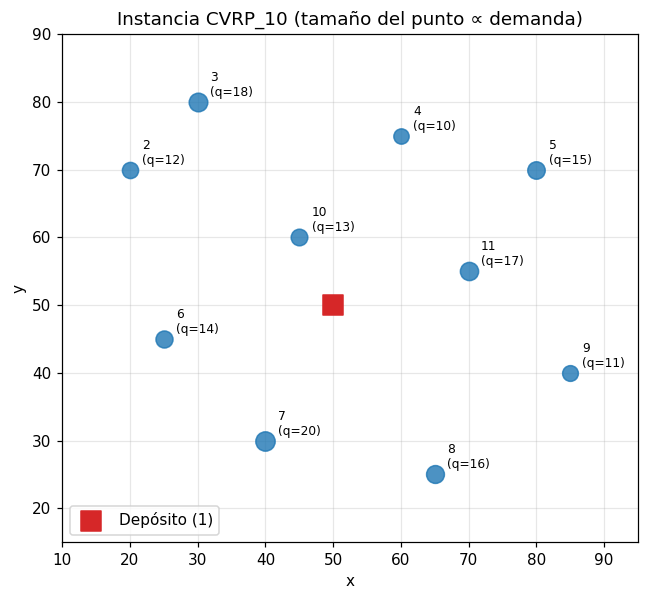

In [3]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for i in CLIENTES:
    ax.scatter(*coords[i], s=40 + 6 * q[i], c="tab:blue", alpha=0.8, zorder=3)
    ax.annotate(f"{i}\n(q={q[i]})", coords[i], textcoords="offset points", xytext=(8, 4), fontsize=8)
ax.scatter(*coords[DEP], marker="s", s=160, c="tab:red", zorder=4, label="Depósito (1)")
ax.set(xlabel="x", ylabel="y", title="Instancia CVRP_10 (tamaño del punto ∝ demanda)",
       xlim=(10, 95), ylim=(15, 90))
ax.grid(alpha=0.3); ax.legend(loc="lower left"); ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(IMG / "instancia.png"); plt.show()

## 2. Matriz de costos

El costo de ir del nodo $i$ al nodo $j$ es la distancia euclidiana

$$c_{ij} = \sqrt{(x_i-x_j)^2 + (y_i-y_j)^2},$$

por lo que la matriz es simétrica ($c_{ij}=c_{ji}$) con diagonal cero. Se usan distancias reales (sin redondear al entero como en TSPLIB) para no perder precisión.

In [4]:
X = np.array([coords[i] for i in NODOS])
D = np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))
C = {i: {j: float(D[a, b]) for b, j in enumerate(NODOS)} for a, i in enumerate(NODOS)}

df_C = pd.DataFrame(D, index=NODOS, columns=NODOS).round(2)
df_C.to_csv(OUT / "matriz_costos.csv")
df_C

,1,2,3,4,5,6,7,8,9,10,11
1,0.00,36.06,36.06,26.93,36.06,25.50,22.36,29.15,36.40,11.18,20.62
2,36.06,0.00,14.14,40.31,60.00,25.50,44.72,63.64,71.59,26.93,52.20
3,36.06,14.14,0.00,30.41,50.99,35.36,50.99,65.19,68.01,25.00,47.17
4,26.93,40.31,30.41,0.00,20.62,46.10,49.24,50.25,43.01,21.21,22.36
5,36.06,60.00,50.99,20.62,0.00,60.42,56.57,47.43,30.41,36.40,18.03
6,25.50,25.50,35.36,46.10,60.42,0.00,21.21,44.72,60.21,25.00,46.10
7,22.36,44.72,50.99,49.24,56.57,21.21,0.00,25.50,46.10,30.41,39.05
8,29.15,63.64,65.19,50.25,47.43,44.72,25.50,0.00,25.00,40.31,30.41
9,36.40,71.59,68.01,43.01,30.41,60.21,46.10,25.00,0.00,44.72,21.21
10,11.18,26.93,25.00,21.21,36.40,25.00,30.41,40.31,44.72,0.00,25.50


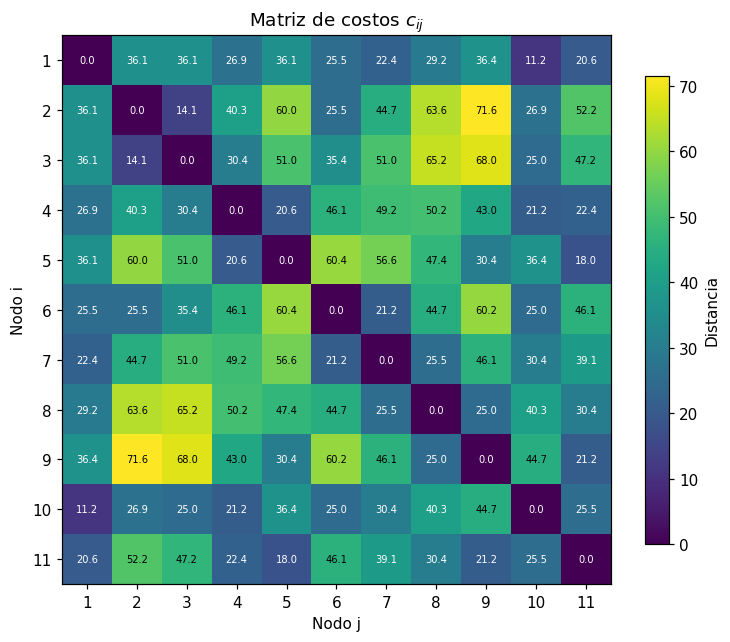

In [5]:
def tabla_latex(df, archivo, caption, label, fmt="{:.2f}", col_index="", resize=False):
    # Escribe un DataFrame como tabla booktabs (sin depender de jinja2).
    cols = "l" + "r" * len(df.columns)
    filas = []
    for idx, fila in df.iterrows():
        celdas = [fmt.format(v) if isinstance(v, (float, np.floating)) else str(v) for v in fila]
        filas.append(" & ".join([str(idx)] + celdas) + r" \\")
    cuerpo = "\n".join(filas)
    encabezado = " & ".join([col_index] + [str(c) for c in df.columns]) + r" \\"
    tabular = (f"\\begin{{tabular}}{{{cols}}}\n\\toprule\n{encabezado}\n\\midrule\n"
               f"{cuerpo}\n\\bottomrule\n\\end{{tabular}}")
    if resize:
        tabular = f"\\resizebox{{\\textwidth}}{{!}}{{%\n{tabular}}}"
    tex = (f"\\begin{{table}}[H]\n\\centering\n\\caption{{{caption}}}\n\\label{{{label}}}\n"
           f"{tabular}\n\\end{{table}}\n")
    (OUT / archivo).write_text(tex)

tabla_latex(df_C, "matriz_costos.tex", "Matriz de costos $c_{ij}$ (distancia euclidiana) de la instancia CVRP\\_10.",
            "tab:matriz_costos", col_index="$i \\backslash j$", resize=True)
tabla_latex(df_nodos, "instancia.tex", "Coordenadas y demanda de los nodos (nodo 1 = depósito, $Q=50$).",
            "tab:instancia", fmt="{:.0f}", col_index="Nodo")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(D, cmap="viridis")
ax.set_xticks(range(len(NODOS)), NODOS); ax.set_yticks(range(len(NODOS)), NODOS)
for a in range(len(NODOS)):
    for b in range(len(NODOS)):
        ax.text(b, a, f"{D[a, b]:.1f}", ha="center", va="center", fontsize=6.5,
                color="white" if D[a, b] < D.max() * 0.6 else "black")
ax.set(xlabel="Nodo j", ylabel="Nodo i", title="Matriz de costos $c_{ij}$")
fig.colorbar(im, ax=ax, shrink=0.8, label="Distancia")
fig.tight_layout(); fig.savefig(IMG / "matriz_costos.png"); plt.show()

## 3. Funciones de evaluación y graficado

Una solución es una lista de rutas; cada ruta es la secuencia de clientes visitados (el depósito al inicio y al final está implícito).

- **Función objetivo**: $Z = \sum_{r}\sum_{(i,j)\in r} c_{ij}$.
- **Espacio desperdiciado** de la ruta $r$: $\displaystyle w_r = \frac{Q - \sum_{i\in r} q_i}{Q}\times 100\%$.

In [6]:
def costo_ruta(ruta):
    camino = [DEP] + list(ruta) + [DEP]
    return sum(C[a][b] for a, b in zip(camino, camino[1:]))

def costo_total(rutas):
    return sum(costo_ruta(r) for r in rutas)

def es_factible(rutas):
    visitados = sorted(i for r in rutas for i in r)
    return visitados == sorted(CLIENTES) and all(sum(q[i] for i in r) <= Q for r in rutas)

def resumen_rutas(rutas):
    filas = []
    for k, r in enumerate(rutas, 1):
        carga = sum(q[i] for i in r)
        filas.append({
            "ruta": f"R{k}",
            "secuencia": " - ".join(map(str, [DEP] + list(r) + [DEP])),
            "carga": carga,
            "costo": round(costo_ruta(r), 2),
            "desperdicio_%": round(100 * (Q - carga) / Q, 2),
        })
    df = pd.DataFrame(filas).set_index("ruta")
    total = sum(sum(q[i] for i in r) for r in rutas)
    df.loc["Total"] = ["", total, round(costo_total(rutas), 2), round(100 * (len(rutas) * Q - total) / (len(rutas) * Q), 2)]
    return df

COLORES = plt.cm.tab10.colors

def graficar_rutas(rutas, titulo, archivo):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for k, r in enumerate(rutas):
        camino = [DEP] + list(r) + [DEP]
        xs, ys = zip(*(coords[i] for i in camino))
        carga = sum(q[i] for i in r)
        ax.plot(xs, ys, "-", color=COLORES[k], lw=2,
                label=f"R{k+1}: carga {carga}/{Q}, costo {costo_ruta(r):.2f}")
        for a, b in zip(camino, camino[1:]):
            (x0, y0), (x1, y1) = coords[a], coords[b]
            ax.annotate("", xy=(x0 + 0.55 * (x1 - x0), y0 + 0.55 * (y1 - y0)), xytext=(x0, y0),
                        arrowprops=dict(arrowstyle="-|>", color=COLORES[k], lw=1.5))
    for i in CLIENTES:
        ax.scatter(*coords[i], s=90, c="white", edgecolors="k", zorder=3)
        ax.annotate(str(i), coords[i], ha="center", va="center", fontsize=7, zorder=4)
    ax.scatter(*coords[DEP], marker="s", s=170, c="tab:red", zorder=4)
    ax.annotate("1", coords[DEP], ha="center", va="center", fontsize=7, color="white", zorder=5)
    ax.set(xlabel="x", ylabel="y", title=f"{titulo}\nZ = {costo_total(rutas):.2f}, {len(rutas)} rutas",
           xlim=(10, 95), ylim=(15, 90))
    ax.grid(alpha=0.3); ax.set_aspect("equal")
    ax.legend(fontsize=7.5, loc="lower left")
    fig.tight_layout(); fig.savefig(IMG / archivo); plt.show()

## 4. Solución manual: heurística del vecino más cercano

Procedimiento (fácil de hacer a mano con la matriz de costos):

1. Salir del depósito con el vehículo vacío.
2. Desde el nodo actual, ir al cliente **no visitado más cercano cuya demanda quepa** en la capacidad restante.
3. Si ningún cliente cabe, regresar al depósito y abrir una nueva ruta.
4. Repetir hasta visitar todos los clientes.

In [7]:
def vecino_mas_cercano(verbose=True):
    pendientes = set(CLIENTES)
    rutas = []
    while pendientes:
        ruta, carga, actual = [], 0, DEP
        while True:
            factibles = [j for j in pendientes if carga + q[j] <= Q]
            if not factibles:
                break
            j = min(factibles, key=lambda j: C[actual][j])
            if verbose:
                print(f"  R{len(rutas)+1}: {actual} -> {j}  (c={C[actual][j]:6.2f}, carga {carga}+{q[j]}={carga+q[j]})")
            ruta.append(j); carga += q[j]; pendientes.remove(j); actual = j
        if verbose:
            print(f"  R{len(rutas)+1}: {actual} -> {DEP}  (c={C[actual][DEP]:6.2f})  regreso al depósito\n")
        rutas.append(ruta)
    return rutas

rutas_manual = vecino_mas_cercano()
assert es_factible(rutas_manual)
df_manual = resumen_rutas(rutas_manual)
df_manual

  R1: 1 -> 10  (c= 11.18, carga 0+13=13)
  R1: 10 -> 4  (c= 21.21, carga 13+10=23)
  R1: 4 -> 5  (c= 20.62, carga 23+15=38)
  R1: 5 -> 9  (c= 30.41, carga 38+11=49)
  R1: 9 -> 1  (c= 36.40)  regreso al depósito

  R2: 1 -> 11  (c= 20.62, carga 0+17=17)
  R2: 11 -> 8  (c= 30.41, carga 17+16=33)
  R2: 8 -> 6  (c= 44.72, carga 33+14=47)
  R2: 6 -> 1  (c= 25.50)  regreso al depósito

  R3: 1 -> 7  (c= 22.36, carga 0+20=20)
  R3: 7 -> 2  (c= 44.72, carga 20+12=32)
  R3: 2 -> 3  (c= 14.14, carga 32+18=50)
  R3: 3 -> 1  (c= 36.06)  regreso al depósito



,secuencia,carga,costo,desperdicio_%
ruta,,,,
R1,1 - 10 - 4 - 5 - 9 - 1,49,119.82,2.00
R2,1 - 11 - 8 - 6 - 1,47,121.25,6.00
R3,1 - 7 - 2 - 3 - 1,50,117.28,0.00
Total,,146,358.35,2.67


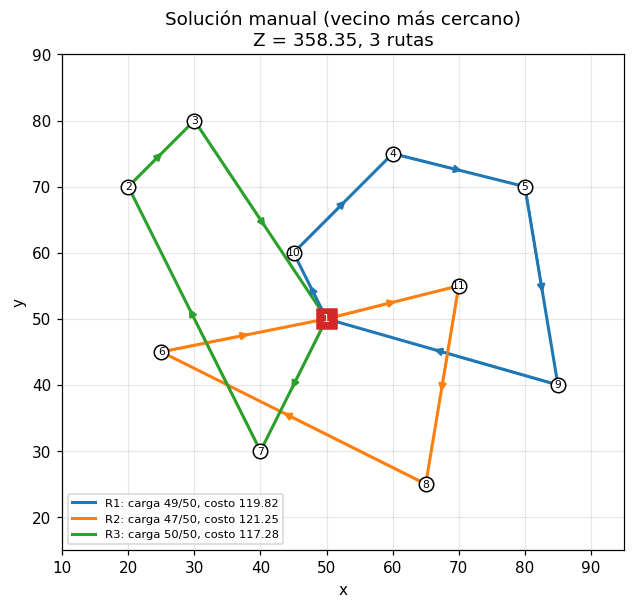

In [8]:
graficar_rutas(rutas_manual, "Solución manual (vecino más cercano)", "rutas_manual.png")

## 5. Definición del problema y modelo matemático

**Conjuntos y parámetros**

| Símbolo | Descripción |
|---|---|
| $V=\{1,\dots,11\}$ | Nodos; $1$ es el depósito |
| $V^+ = V\setminus\{1\}$ | Clientes |
| $c_{ij}$ | Costo (distancia) del arco $(i,j)$ |
| $q_i$ | Demanda del cliente $i$ |
| $Q$ | Capacidad de cada vehículo (50) |
| $K_{\min}=\lceil \sum q_i / Q\rceil$ | Mínimo de vehículos (3) |

**Variables de decisión**

- $x_{ij}\in\{0,1\}$: 1 si un vehículo recorre el arco $(i,j)$.
- $u_i \in [q_i, Q]$: carga acumulada del vehículo al salir del cliente $i$ (elimina subtours).
- $K = \sum_{j\in V^+} x_{1j}$: número de vehículos (rutas) utilizados.

**Modelo (formulación de dos índices con restricciones MTZ de carga)**

$$
\begin{aligned}
\min\; Z &= \sum_{i\in V}\sum_{j\in V,\, j\neq i} c_{ij}\,x_{ij} \\
\text{s.a.}\quad
& \sum_{i\in V,\, i\neq j} x_{ij} = 1 && \forall j\in V^+ \quad\text{(cada cliente recibe una visita)}\\
& \sum_{j\in V,\, j\neq i} x_{ij} = 1 && \forall i\in V^+ \quad\text{(y sale una vez)}\\
& \sum_{j\in V^+} x_{1j} = \sum_{i\in V^+} x_{i1} \ge K_{\min} && \text{(rutas que salen = rutas que regresan)}\\
& u_j \ge u_i + q_j - Q(1-x_{ij}) && \forall i\neq j\in V^+ \quad\text{(capacidad / sin subtours)}\\
& q_i \le u_i \le Q && \forall i\in V^+\\
& x_{ij}\in\{0,1\}
\end{aligned}
$$

### Diagrama de relaciones del modelo

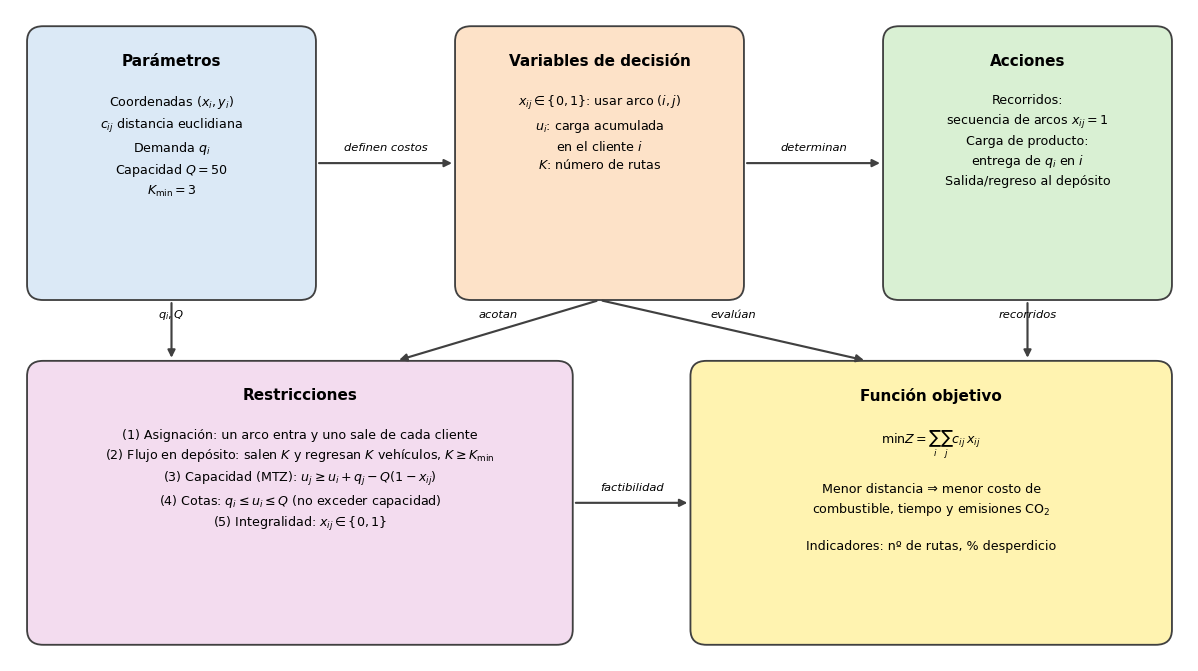

In [9]:
fig, ax = plt.subplots(figsize=(11, 6.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 6.4); ax.axis("off")

def caja(x, y, w, h, titulo, texto, color):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.15",
                                fc=color, ec="0.25", lw=1.2))
    ax.text(x + w / 2, y + h - 0.22, titulo, ha="center", va="top", fontsize=10, weight="bold")
    ax.text(x + w / 2, y + h - 0.62, texto, ha="center", va="top", fontsize=8.3, linespacing=1.45)

def flecha(p0, p1, texto=""):
    ax.annotate("", xy=p1, xytext=p0, arrowprops=dict(arrowstyle="-|>", lw=1.4, color="0.25"))
    if texto:
        ax.text((p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.12, texto, ha="center", fontsize=7.5, style="italic")

caja(0.2, 3.6, 2.6, 2.6, "Parámetros",
     "Coordenadas $(x_i, y_i)$\n$c_{ij}$ distancia euclidiana\nDemanda $q_i$\nCapacidad $Q = 50$\n$K_{\\min} = 3$", "#dbe9f6")
caja(4.2, 3.6, 2.6, 2.6, "Variables de decisión",
     "$x_{ij}\\in\\{0,1\\}$: usar arco $(i,j)$\n$u_i$: carga acumulada\nen el cliente $i$\n$K$: número de rutas", "#fde2c8")
caja(8.2, 3.6, 2.6, 2.6, "Acciones",
     "Recorridos:\nsecuencia de arcos $x_{ij}=1$\nCarga de producto:\nentrega de $q_i$ en $i$\nSalida/regreso al depósito", "#d9f0d3")
caja(0.2, 0.2, 5.0, 2.7, "Restricciones",
     "(1) Asignación: un arco entra y uno sale de cada cliente\n"
     "(2) Flujo en depósito: salen $K$ y regresan $K$ vehículos, $K\\geq K_{\\min}$\n"
     "(3) Capacidad (MTZ): $u_j \\geq u_i + q_j - Q(1-x_{ij})$\n"
     "(4) Cotas: $q_i \\leq u_i \\leq Q$ (no exceder capacidad)\n"
     "(5) Integralidad: $x_{ij}\\in\\{0,1\\}$", "#f3dcef")
caja(6.4, 0.2, 4.4, 2.7, "Función objetivo",
     "$\\min Z = \\sum_i \\sum_j c_{ij}\\, x_{ij}$\n\nMenor distancia ⇒ menor costo de\ncombustible, tiempo y emisiones CO$_2$\n\nIndicadores: nº de rutas, % desperdicio", "#fff3b0")

flecha((2.85, 4.9), (4.15, 4.9), "definen costos")
flecha((6.85, 4.9), (8.15, 4.9), "determinan")
flecha((5.5, 3.55), (3.6, 2.95), "acotan")
flecha((5.5, 3.55), (8.0, 2.95), "evalúan")
flecha((1.5, 3.55), (1.5, 2.95), "$q_i, Q$")
flecha((9.5, 3.55), (9.5, 2.95), "recorridos")
flecha((5.25, 1.55), (6.35, 1.55), "factibilidad")
fig.tight_layout(); fig.savefig(IMG / "diagrama_modelo.png", bbox_inches="tight"); plt.show()

## 6. Solución exacta con PuLP (solver CBC)

In [10]:
def resolver_cvrp_exacto(K_fijo=None, tiempo_limite=600):
    arcos = [(i, j) for i in NODOS for j in NODOS if i != j]
    prob = pulp.LpProblem("CVRP_10", pulp.LpMinimize)
    x = pulp.LpVariable.dicts("x", arcos, cat="Binary")
    u = {i: pulp.LpVariable(f"u_{i}", lowBound=q[i], upBound=Q) for i in CLIENTES}

    prob += pulp.lpSum(C[i][j] * x[i, j] for i, j in arcos), "Distancia_total"
    for j in CLIENTES:
        prob += pulp.lpSum(x[i, j] for i in NODOS if i != j) == 1, f"entra_{j}"
    for i in CLIENTES:
        prob += pulp.lpSum(x[i, j] for j in NODOS if j != i) == 1, f"sale_{i}"
    salen = pulp.lpSum(x[DEP, j] for j in CLIENTES)
    prob += salen == pulp.lpSum(x[i, DEP] for i in CLIENTES), "flujo_deposito"
    if K_fijo is None:
        prob += salen >= K_MIN, "min_vehiculos"
    else:
        prob += salen == K_fijo, "flota_fija"
    for i in CLIENTES:
        for j in CLIENTES:
            if i != j:
                prob += u[j] >= u[i] + q[j] - Q * (1 - x[i, j]), f"mtz_{i}_{j}"

    t0 = time.perf_counter()
    prob.solve(pulp.PULP_CBC_CMD(msg=False, timeLimit=tiempo_limite))
    t = time.perf_counter() - t0

    # Reconstruir rutas siguiendo los arcos activos desde el depósito
    sucesor = {i: j for (i, j) in arcos if x[i, j].value() > 0.5 and i != DEP}
    rutas = []
    for j in CLIENTES:
        if x[DEP, j].value() > 0.5:
            ruta, actual = [], j
            while actual != DEP:
                ruta.append(actual); actual = sucesor[actual]
            rutas.append(ruta)
    return prob, rutas, t

prob, rutas_exacto, t_exacto = resolver_cvrp_exacto()
print("Estado:", pulp.LpStatus[prob.status])
print(f"Variables: {len(prob.variables())}  |  Restricciones: {len(prob.constraints)}")
print(f"Z* = {pulp.value(prob.objective):.4f}   |   tiempo = {t_exacto:.3f} s")
assert es_factible(rutas_exacto)
df_exacto = resumen_rutas(rutas_exacto)
df_exacto

Estado: Optimal
Variables: 120  |  Restricciones: 112
Z* = 318.9895   |   tiempo = 1.232 s


,secuencia,carga,costo,desperdicio_%
ruta,,,,
R1,1 - 6 - 2 - 3 - 1,44,101.19,12.0
R2,1 - 7 - 8 - 9 - 1,47,109.26,6.0
R3,1 - 10 - 1,13,22.36,74.0
R4,1 - 11 - 5 - 4 - 1,42,86.18,16.0
Total,,146,318.99,27.0


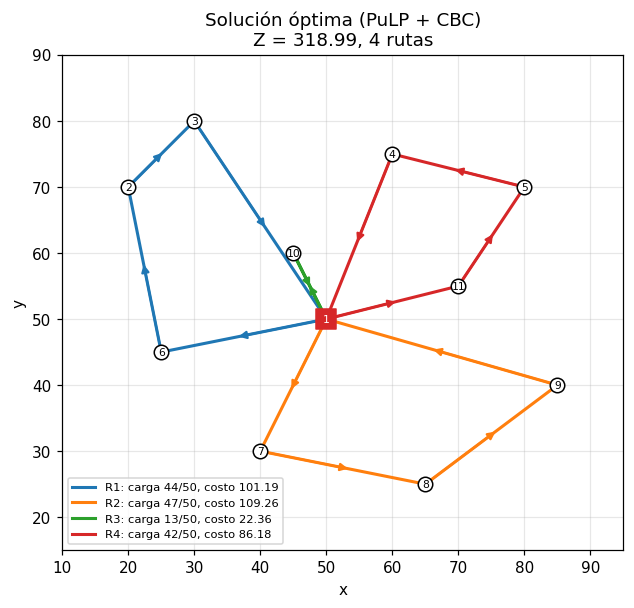

In [11]:
graficar_rutas(rutas_exacto, "Solución óptima (PuLP + CBC)", "rutas_exacto.png")

### 6.1 Variante con flota fija de $K = K_{\min} = 3$ vehículos

El óptimo anterior deja libre el número de rutas. Si la empresa sólo dispone del mínimo de vehículos ($K=3$), se fija $\sum_j x_{1j} = 3$. Esto obliga a llenar más los camiones (menos desperdicio), a cambio de recorrer más distancia.

In [12]:
prob_k3, rutas_k3, t_k3 = resolver_cvrp_exacto(K_fijo=K_MIN)
print("Estado:", pulp.LpStatus[prob_k3.status])
print(f"Z*(K=3) = {pulp.value(prob_k3.objective):.4f}   |   tiempo = {t_k3:.3f} s")
assert es_factible(rutas_k3)
df_k3 = resumen_rutas(rutas_k3)
df_k3

Estado: Optimal
Z*(K=3) = 339.1647   |   tiempo = 6.458 s


,secuencia,carga,costo,desperdicio_%
ruta,,,,
R1,1 - 6 - 7 - 8 - 1,50,101.36,0.00
R2,1 - 10 - 4 - 5 - 9 - 1,49,119.82,2.00
R3,1 - 11 - 3 - 2 - 1,47,117.98,6.00
Total,,146,339.16,2.67


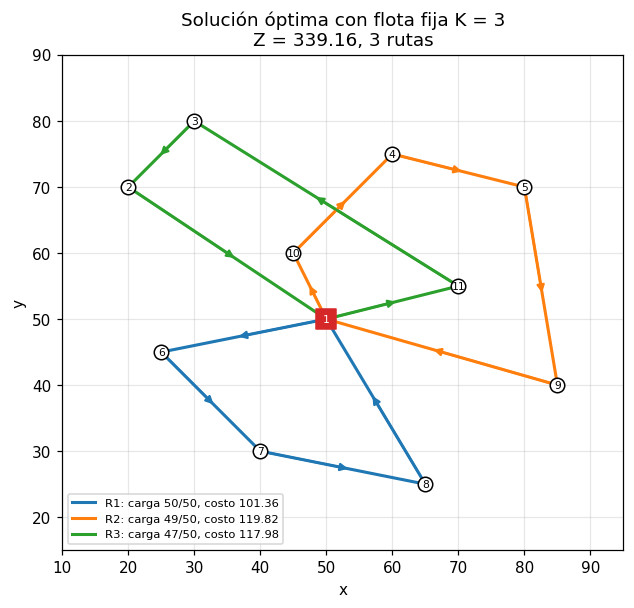

In [13]:
graficar_rutas(rutas_k3, "Solución óptima con flota fija K = 3", "rutas_exacto_k3.png")

## 7. Algoritmo programado: Ahorros de Clarke & Wright + 2-opt

**Clarke & Wright (versión paralela).** Se parte de una ruta por cliente $(1\to i\to 1)$. Unir las rutas que terminan en $i$ y empiezan en $j$ ahorra

$$s_{ij} = c_{1i} + c_{1j} - c_{ij}.$$

Los ahorros se ordenan de mayor a menor y se fusionan rutas siempre que (a) $i$ y $j$ estén en extremos de rutas distintas y (b) la carga combinada no exceda $Q$.

**2-opt.** Sobre cada ruta resultante se invierten segmentos mientras se reduzca la distancia, eliminando cruces.

In [14]:
def clarke_wright():
    rutas = {i: [i] for i in CLIENTES}          # id de ruta -> secuencia
    ruta_de = {i: i for i in CLIENTES}          # cliente -> id de ruta
    carga = {i: q[i] for i in CLIENTES}
    ahorros = sorted(((C[DEP][i] + C[DEP][j] - C[i][j], i, j) for i, j in combinations(CLIENTES, 2)),
                     reverse=True)
    for s, i, j in ahorros:
        ri, rj = ruta_de[i], ruta_de[j]
        if s <= 0 or ri == rj or carga[ri] + carga[rj] > Q:
            continue
        A, B = rutas[ri], rutas[rj]
        if A[-1] == i and B[0] == j:
            nueva = A + B
        elif A[0] == i and B[-1] == j:
            nueva = B + A
        elif A[0] == i and B[0] == j:
            nueva = A[::-1] + B
        elif A[-1] == i and B[-1] == j:
            nueva = A + B[::-1]
        else:
            continue                             # i o j son nodos interiores
        rutas[ri] = nueva
        carga[ri] += carga.pop(rj)
        del rutas[rj]
        for k in B:
            ruta_de[k] = ri
    return list(rutas.values()), ahorros

def dos_opt(ruta):
    camino = [DEP] + list(ruta) + [DEP]
    mejora = True
    while mejora:
        mejora = False
        for a in range(1, len(camino) - 2):
            for b in range(a + 1, len(camino) - 1):
                delta = (C[camino[a - 1]][camino[b]] + C[camino[a]][camino[b + 1]]
                         - C[camino[a - 1]][camino[a]] - C[camino[b]][camino[b + 1]])
                if delta < -1e-9:
                    camino[a:b + 1] = camino[a:b + 1][::-1]
                    mejora = True
    return camino[1:-1]

def algoritmo_cw_2opt():
    rutas, _ = clarke_wright()
    return [dos_opt(r) for r in rutas]

rutas_cw, ahorros = clarke_wright()
print("Top 10 ahorros s_ij:")
display(pd.DataFrame(ahorros[:10], columns=["s_ij", "i", "j"]).round(2))
print(f"Clarke & Wright: Z = {costo_total(rutas_cw):.4f}, rutas = {rutas_cw}")

rutas_heur = algoritmo_cw_2opt()
assert es_factible(rutas_heur)
print(f"C&W + 2-opt:     Z = {costo_total(rutas_heur):.4f}, rutas = {rutas_heur}")
df_heur = resumen_rutas(rutas_heur)
df_heur

Top 10 ahorros s_ij:


,s_ij,i,j
0,57.97,2,3
1,42.37,4,5
2,42.04,5,9
3,40.56,8,9
4,38.64,5,11
5,36.06,2,6
6,35.80,9,11
7,32.57,3,4
8,26.64,6,7
9,26.20,3,6


Clarke & Wright: Z = 339.2529, rutas = [[6, 2, 3], [10, 4, 5, 9], [7, 8], [11]]
C&W + 2-opt:     Z = 339.2529, rutas = [[6, 2, 3], [10, 4, 5, 9], [7, 8], [11]]


,secuencia,carga,costo,desperdicio_%
ruta,,,,
R1,1 - 6 - 2 - 3 - 1,44,101.19,12.0
R2,1 - 10 - 4 - 5 - 9 - 1,49,119.82,2.0
R3,1 - 7 - 8 - 1,36,77.01,28.0
R4,1 - 11 - 1,17,41.23,66.0
Total,,146,339.25,27.0


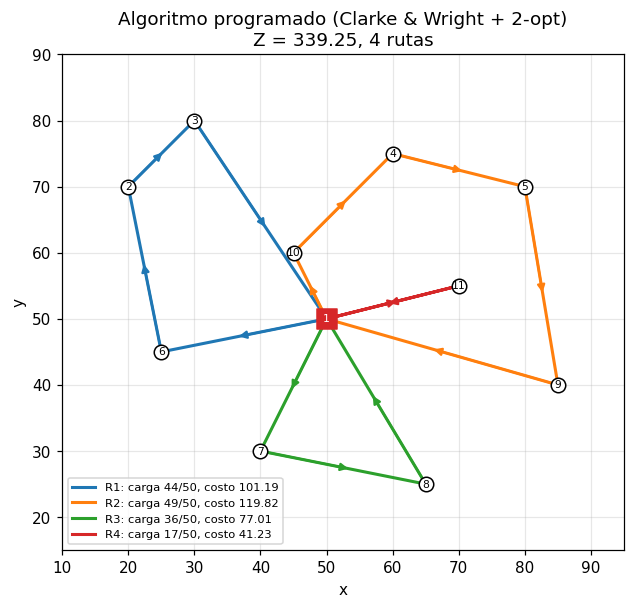

In [15]:
graficar_rutas(rutas_heur, "Algoritmo programado (Clarke & Wright + 2-opt)", "rutas_heuristica.png")

## 8. Comparación: costo, tiempo de cómputo y GAP

Tomando la solución exacta como referencia:

$$\text{GAP}_{\text{costo}} = \frac{Z_{\text{método}} - Z^*}{Z^*}\times 100\%, \qquad
\Delta_{\text{tiempo}} = \frac{t_{\text{método}} - t_{\text{exacto}}}{t_{\text{exacto}}}\times 100\%.$$

Los tiempos de las heurísticas son tan pequeños que se promedian sobre 1000 ejecuciones; el del modelo exacto se promedia sobre 5 resoluciones (incluye construcción del modelo y llamada a CBC).

In [16]:
def cronometrar(f, repeticiones):
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        f()
    return (time.perf_counter() - t0) / repeticiones

t_manual = cronometrar(lambda: vecino_mas_cercano(verbose=False), 1000)
t_heur = cronometrar(algoritmo_cw_2opt, 1000)
t_exacto = cronometrar(lambda: resolver_cvrp_exacto(), 5)
t_k3 = cronometrar(lambda: resolver_cvrp_exacto(K_fijo=K_MIN), 5)

Z_opt = costo_total(rutas_exacto)
metodos = {
    "Exacto (PuLP + CBC)": (rutas_exacto, t_exacto),
    "Exacto, flota fija K=3": (rutas_k3, t_k3),
    "Vecino más cercano (manual)": (rutas_manual, t_manual),
    "Clarke & Wright + 2-opt": (rutas_heur, t_heur),
}
filas = []
for nombre, (rutas, t) in metodos.items():
    Z = costo_total(rutas)
    carga_total = sum(q[i] for r in rutas for i in r)
    filas.append({
        "Método": nombre,
        "Costo Z": round(Z, 2),
        "Rutas": len(rutas),
        "Desperdicio prom. %": round(100 * (len(rutas) * Q - carga_total) / (len(rutas) * Q), 2),
        "Tiempo (s)": t,
        "GAP costo %": round(100 * (Z - Z_opt) / Z_opt, 2),
        "Δ tiempo vs exacto %": round(100 * (t - t_exacto) / t_exacto, 4),
        "Aceleración (×)": round(t_exacto / t, 1),
    })
df_comp = pd.DataFrame(filas).set_index("Método")
pd.options.display.float_format = "{:.6g}".format
df_comp

,Costo Z,Rutas,Desperdicio prom. %,Tiempo (s),GAP costo %,Δ tiempo vs exacto %,Aceleración (×)
Método,,,,,,,
Exacto (PuLP + CBC),318.99,4,27,1.15856,0,0,1
"Exacto, flota fija K=3",339.16,3,2.67,6.52071,6.32,462.827,0.2
Vecino más cercano (manual),358.35,3,2.67,1.15371e-05,12.34,-99.999,100420
Clarke & Wright + 2-opt,339.25,4,27,2.1272e-05,6.35,-99.9982,54464.2


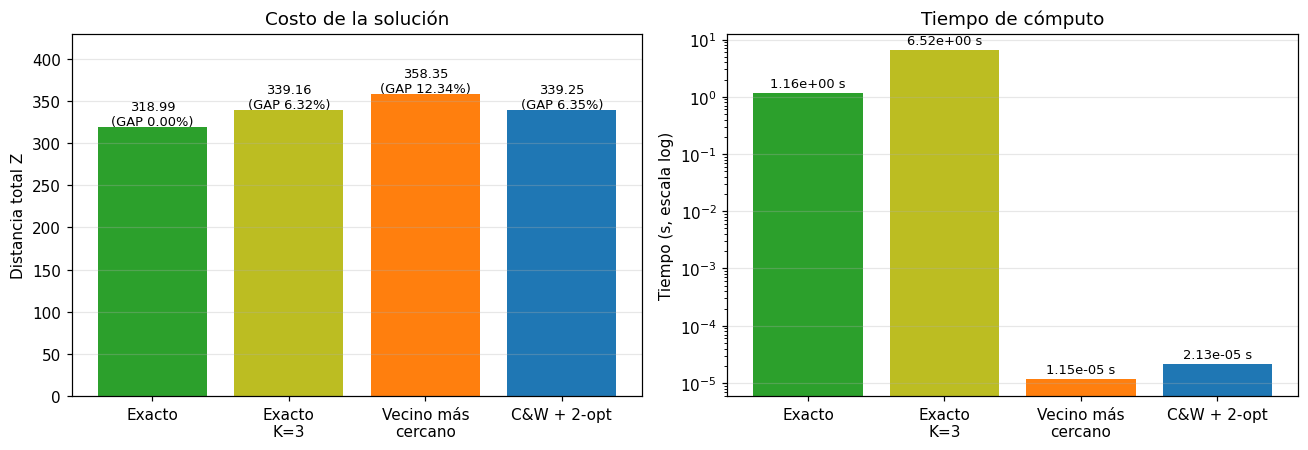

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
nombres = ["Exacto", "Exacto\nK=3", "Vecino más\ncercano", "C&W + 2-opt"]
colores = ["tab:green", "tab:olive", "tab:orange", "tab:blue"]
axs[0].bar(nombres, df_comp["Costo Z"], color=colores)
for k, (z, g) in enumerate(zip(df_comp["Costo Z"], df_comp["GAP costo %"])):
    axs[0].text(k, z + 3, f"{z:.2f}\n(GAP {g:.2f}%)", ha="center", fontsize=8.5)
axs[0].set(ylabel="Distancia total Z", title="Costo de la solución", ylim=(0, df_comp["Costo Z"].max() * 1.2))
axs[1].bar(nombres, df_comp["Tiempo (s)"], color=colores)
axs[1].set_yscale("log")
for k, t in enumerate(df_comp["Tiempo (s)"]):
    axs[1].text(k, t * 1.3, f"{t:.2e} s", ha="center", fontsize=8.5)
axs[1].set(ylabel="Tiempo (s, escala log)", title="Tiempo de cómputo")
for ax in axs:
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout(); fig.savefig(IMG / "comparacion.png"); plt.show()

## 9. Exportar tablas y resultados para el reporte LaTeX

In [18]:
def exportar_rutas(df, archivo, caption, label):
    df2 = df.copy()
    df2.columns = ["Secuencia", "Carga", "Costo", "Desperdicio (\\%)"]
    tabla_latex(df2, archivo, caption, label, col_index="Ruta")

exportar_rutas(df_manual, "rutas_manual.tex", "Rutas obtenidas con el vecino más cercano (solución manual).", "tab:rutas_manual")
exportar_rutas(df_exacto, "rutas_exacto.tex", "Rutas óptimas obtenidas con PuLP + CBC.", "tab:rutas_exacto")
exportar_rutas(df_k3, "rutas_exacto_k3.tex", "Rutas óptimas con flota fija de $K=3$ vehículos.", "tab:rutas_exacto_k3")
exportar_rutas(df_heur, "rutas_heuristica.tex", "Rutas obtenidas con Clarke \\& Wright + 2-opt.", "tab:rutas_heuristica")

df_comp_tex = df_comp.copy()
df_comp_tex["Tiempo (s)"] = df_comp_tex["Tiempo (s)"].map(lambda t: f"{t:.2e}")
df_comp_tex.index = [s.replace("&", "\\&") for s in df_comp_tex.index]
df_comp_tex["Δ tiempo vs exacto %"] = df_comp_tex["Δ tiempo vs exacto %"].map(lambda v: f"{v:.3f}")
df_comp_tex.columns = ["Costo $Z$", "Rutas", "Desp. prom. (\\%)", "Tiempo (s)", "GAP costo (\\%)",
                       "$\\Delta$ tiempo (\\%)", "Aceleración ($\\times$)"]
tabla_latex(df_comp_tex, "comparacion.tex", "Comparación de costo y tiempo de cómputo respecto al óptimo.",
            "tab:comparacion", col_index="Método", resize=True)

resumen = {
    "demanda_total": demanda_total, "capacidad": Q, "K_min": K_MIN,
    "metodos": {n: {"rutas": r, "costo": costo_total(r), "num_rutas": len(r), "tiempo_s": t,
                    "gap_costo_pct": 100 * (costo_total(r) - Z_opt) / Z_opt}
                for n, (r, t) in metodos.items()},
}
(OUT / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False))
print("Archivos generados:")
for p in sorted(list(OUT.iterdir()) + list(IMG.iterdir())):
    print("  ", p)

Archivos generados:
   Images/comparacion.png
   Images/diagrama_modelo.png
   Images/instancia.png
   Images/matriz_costos.png
   Images/rutas_exacto.png
   Images/rutas_exacto_k3.png
   Images/rutas_heuristica.png
   Images/rutas_manual.png
   resultados/comparacion.tex
   resultados/instancia.tex
   resultados/matriz_costos.csv
   resultados/matriz_costos.tex
   resultados/resumen.json
   resultados/rutas_exacto.tex
   resultados/rutas_exacto_k3.tex
   resultados/rutas_heuristica.tex
   resultados/rutas_manual.tex
